# PRAKTIKUM PENAMBANGAN DATA (PPD)
## MODUL 7: IMBALANCED DATASET & DATA BALANCING

* **Nama**: Januarsyah Akbar
* **NIM**: 24/535846/SV/24314
* **Kelas**: B2
* **Mata Kuliah**: Praktikum Penambangan Data (SVPL214610)
* **Program Studi**: D4 Teknologi Rekayasa Perangkat Lunak, Sekolah Vokasi UGM

---

## A. LANGKAH PERCOBAAN: IMBALANCED DATASET (STROKE DATASET)
Dataset: [Stroke Prediction Dataset](https://raw.githubusercontent.com/ganjar87/data_science_practice/refs/heads/main/healthcare-dataset-stroke-data.csv)

### 1. Inisialisasi & Setup Lingkungan Colab / Local
Mempersiapkan dependensi pustaka dan skrip unduh dataset otomatis agar notebook dapat langsung dijalankan di Google Colab maupun secara lokal.

In [1]:
# Setup lingkungan dan unduh dataset otomatis jika dijalankan di Google Colab
import os
import urllib.request
import ssl

ctx = ssl.create_default_context()
ctx.check_hostname = False
ctx.verify_mode = ssl.CERT_NONE

# Cari folder data yang tersedia
DATA_DIR = 'data'
for candidate in ['data', 'P7/project/data', '../data']:
    if os.path.exists(candidate):
        DATA_DIR = candidate
        break
os.makedirs(DATA_DIR, exist_ok=True)

# 1. Dataset Percobaan (Stroke Dataset)
stroke_url = "https://raw.githubusercontent.com/ganjar87/data_science_practice/refs/heads/main/healthcare-dataset-stroke-data.csv"
stroke_local = os.path.join(DATA_DIR, "healthcare-dataset-stroke-data.csv")
if not os.path.exists(stroke_local):
    print("Mengunduh healthcare-dataset-stroke-data.csv...")
    urllib.request.urlretrieve(stroke_url, stroke_local)

# 2. Dataset Tugas 2 (Heart Failure Records Dataset)
heart_url = "https://raw.githubusercontent.com/ganjar87/data_science_practice/main/heart_failure_clinical_records_dataset.csv"
heart_local = os.path.join(DATA_DIR, "heart_failure_clinical_records_dataset.csv")
if not os.path.exists(heart_local):
    print("Mengunduh heart_failure_clinical_records_dataset.csv...")
    urllib.request.urlretrieve(heart_url, heart_local)

print(f"Semua berkas dataset siap digunakan di direktori '{DATA_DIR}'.")

Semua berkas dataset siap digunakan di direktori 'P7/project/data'.


### 2. Import Seluruh Pustaka yang Diperlukan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    precision_recall_curve
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

import warnings
warnings.filterwarnings('ignore')

# Set visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Pustaka berhasil diimpor.")

Pustaka berhasil diimpor.


### 3. Memuat dan Menginspeksi Stroke Prediction Dataset

In [3]:
# Memuat dataset
df = pd.read_csv(os.path.join(DATA_DIR, 'healthcare-dataset-stroke-data.csv'))

# Menampilkan 5 baris teratas
print("Dimensi dataset:", df.shape)
df.head()

Dimensi dataset: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
# Ringkasan informasi kolom dan tipe data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


### 4. Pemeriksaan Missing Values dan Exploratory Data Analysis (EDA)

In [5]:
# Cek missing values
print("Pemeriksaan missing values per fitur:")
df.isnull().sum()

Pemeriksaan missing values per fitur:


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

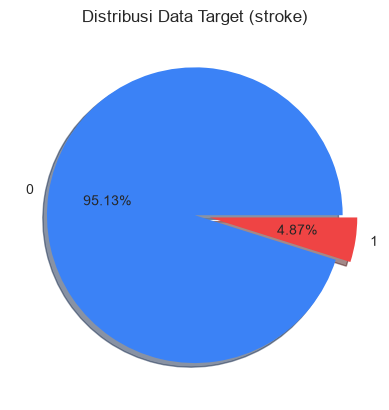

Distribusi Persentase Target (stroke):
 Kelas 0: 95.13%
 Kelas 1: 4.87%


In [6]:
# Visualisasi distribusi data target stroke (Pie Chart)
data = df['stroke'].value_counts()
data.plot(kind='pie', autopct='%.2f%%', colors=['#3b82f6', '#ef4444'], explode=(0, 0.1), shadow=True)
plt.title("Distribusi Data Target (stroke)")
plt.ylabel("")
plt.show()

print("Distribusi Persentase Target (stroke):")
print(f" Kelas 0: {data[0]/len(df)*100:.2f}%")
print(f" Kelas 1: {data[1]/len(df)*100:.2f}%")

### 5. Data Cleaning (Imputasi Nilai Rata-rata pada Kolom BMI)
Pada fitur `bmi` ditemukan 201 missing values. Karena BMI merupakan variabel numerik kontinu, missing value diatasi menggunakan teknik imputasi dengan mengisi nilai kosong menggunakan nilai rata-rata (*mean*).

In [7]:
# Imputasi missing value dengan mean
df['bmi'].fillna(df['bmi'].mean(), inplace=True)

# Cek missing values after imputation
print("Pemeriksaan ulang missing values setelah imputasi mean:")
df.isnull().sum()

Pemeriksaan ulang missing values setelah imputasi mean:


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

### 6. Pemisahan Fitur dan Target serta Encoding Kategorikal

In [8]:
# Menampilkan kolom stroke
df_y = df[['stroke']]
df_y

,stroke
0,1
1,1
2,1
3,1
4,1
...,...
5105,0
5106,0
5107,0
5108,0


### 7. Teknik 1: Random Under Sampling (RUS)
`RandomUnderSampler` menyeimbangkan kelas dengan memangkas secara acak sampel dari kelas mayoritas hingga jumlahnya sama dengan kelas minoritas.

In [9]:
under_sampling = RandomUnderSampler(random_state=0)
df_X = df.drop(['id', 'stroke'], axis=1).copy()
df_y = df['stroke'].copy()

le = LabelEncoder()
df_y = le.fit_transform(df_y)

# Imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# Categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'].astype(str))
df_X['ever_married'] = le.fit_transform(df_X['ever_married'].astype(str))
df_X['work_type'] = le.fit_transform(df_X['work_type'].astype(str))
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'].astype(str))
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'].astype(str))

X = df_X.astype(float).values
y = df_y

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

X_res_rus, y_res_rus = under_sampling.fit_resample(X_train, y_train)

print('sebelum undersampling')
print(pd.DataFrame(y_train).value_counts())
print('setelah undersampling')
print(pd.DataFrame(y_res_rus).value_counts())

sebelum undersampling
0
0    3663
1     169
Name: count, dtype: int64
setelah undersampling
0
0    169
1    169
Name: count, dtype: int64


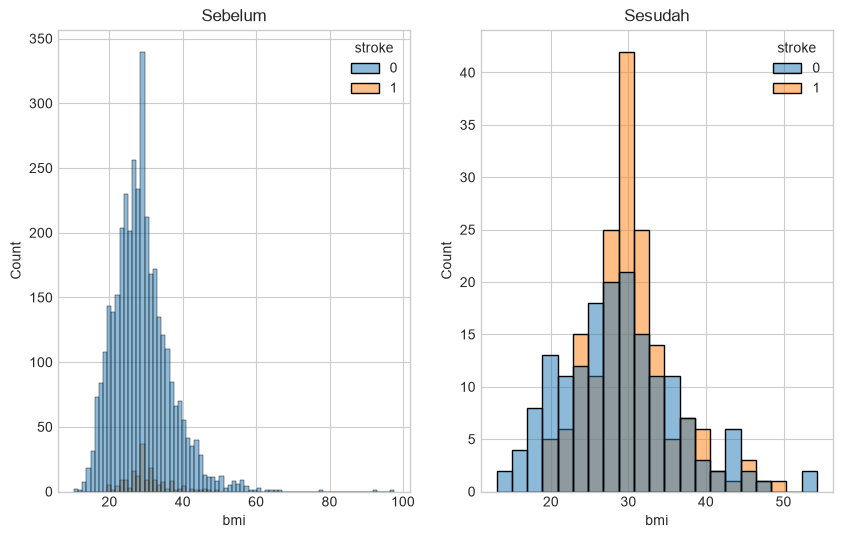

In [10]:
# Visualisasi perbandingan distribusi fitur bmi (histogram)
dfx_ori = pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_res_rus, columns=df_X.columns)
dfy_res = pd.DataFrame(y_res_rus, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi', hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi', hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks(rotation='horizontal')
plt.show()

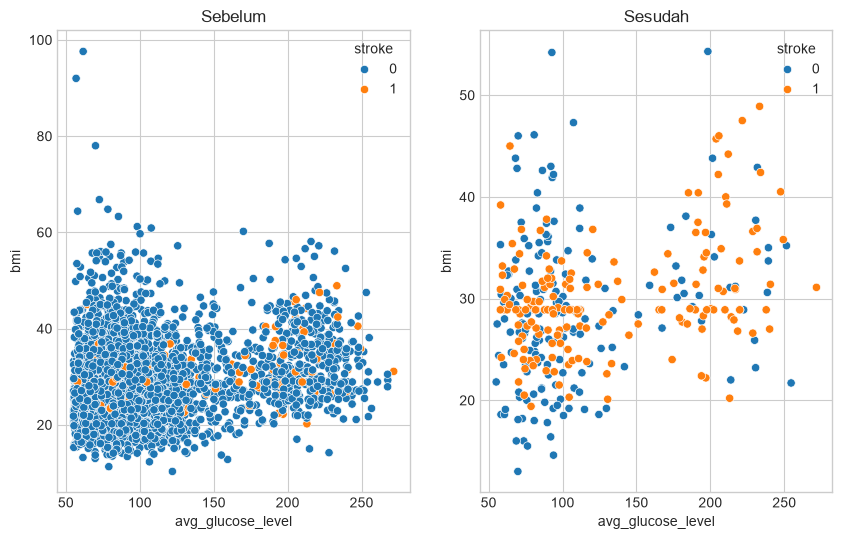

In [11]:
# Visualisasi scatter plot avg_glucose_level vs bmi
f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

### 8. Teknik 2: Random Over Sampling (ROS)
`RandomOverSampler` menduplikasi secara acak sampel yang ada pada kelas minoritas hingga setara dengan kelas mayoritas.

In [12]:
over_sampling = RandomOverSampler(random_state=0)
df_X = df.drop(['id', 'stroke'], axis=1).copy()
df_y = df['stroke'].copy()

# Imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# Categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'].astype(str))
df_X['ever_married'] = le.fit_transform(df_X['ever_married'].astype(str))
df_X['work_type'] = le.fit_transform(df_X['work_type'].astype(str))
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'].astype(str))
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'].astype(str))

X = df_X.astype(float).values
y = df_y.astype(float).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

X_res_ros, y_res_ros = over_sampling.fit_resample(X_train, y_train)

print('sebelum random oversampling')
print(pd.DataFrame(y_train).value_counts())
print('setelah random oversampling')
print(pd.DataFrame(y_res_ros).value_counts())

sebelum random oversampling
0  
0.0    3663
1.0     169
Name: count, dtype: int64
setelah random oversampling
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


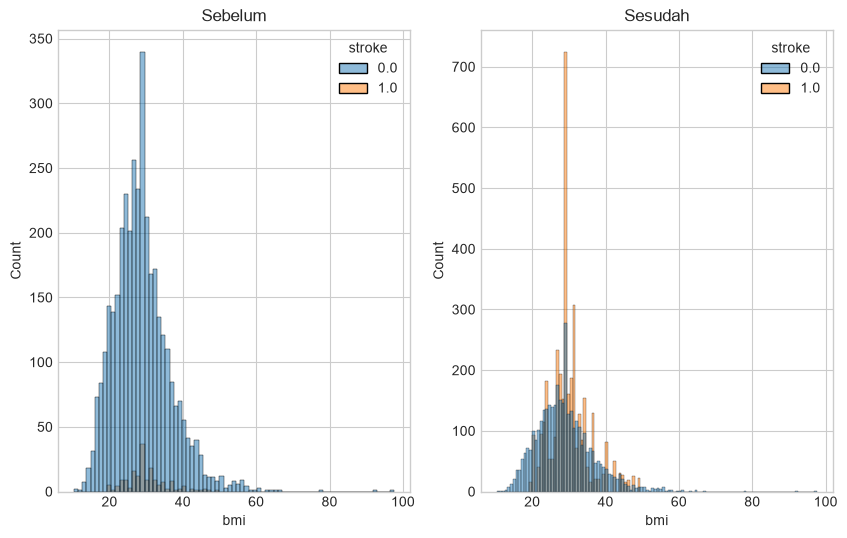

In [13]:
# Visualisasi histogram perbandingan distribusi bmi sebelum dan sesudah oversampling
dfx_ori = pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_res_ros, columns=df_X.columns)
dfy_res = pd.DataFrame(y_res_ros, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi', hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi', hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

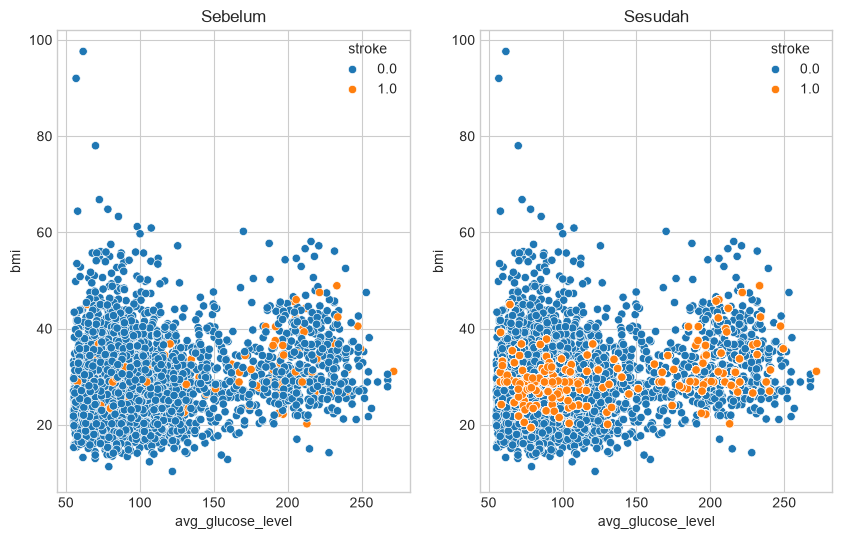

In [14]:
# Visualisasi scatter plot avg_glucose_level vs bmi
f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

### 9. Teknik 3: Synthetic Minority Over-sampling Technique (SMOTE)
SMOTE menciptakan sampel sintetis baru pada kelas minoritas dengan cara melakukan interpolasi linier di sepanjang garis penghubung antar titik sampel tetangga terdekat ($k$-Nearest Neighbors).

In [15]:
df_X = df.drop(['id', 'stroke'], axis=1).copy()
df_y = df['stroke'].copy()

# Imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# Categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'].astype(str))
df_X['ever_married'] = le.fit_transform(df_X['ever_married'].astype(str))
df_X['work_type'] = le.fit_transform(df_X['work_type'].astype(str))
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'].astype(str))
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'].astype(str))

X = df_X.astype(float).values
y = df_y.astype(float).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

smote = SMOTE(random_state=0)
X_res_smote, y_res_smote = smote.fit_resample(X_train, y_train)

print('Sebelum SMOTE')
print(pd.DataFrame(y_train).value_counts())
print('Setelah SMOTE')
print(pd.DataFrame(y_res_smote).value_counts())

Sebelum SMOTE
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah SMOTE
0  
0.0    3663
1.0    3663
Name: count, dtype: int64


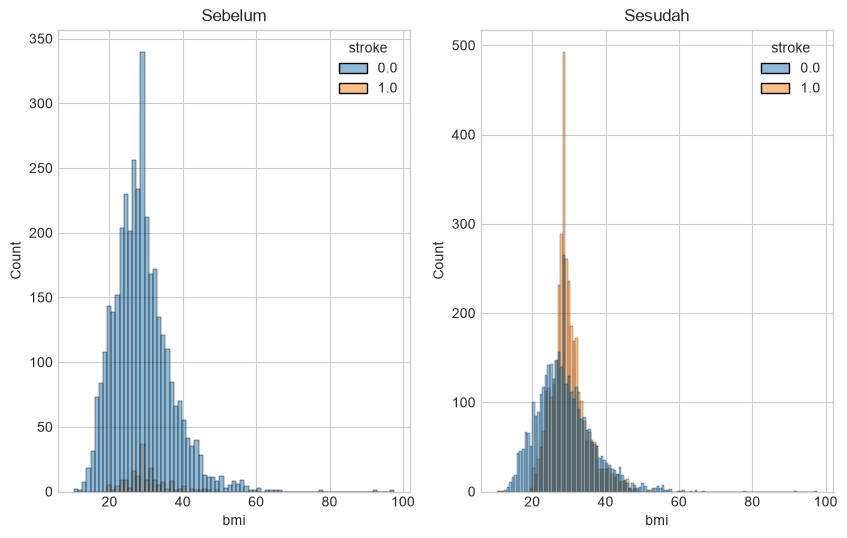

In [16]:
# Visualisasi histogram perbandingan distribusi bmi sebelum dan sesudah SMOTE
dfx_ori = pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_res_smote, columns=df_X.columns)
dfy_res = pd.DataFrame(y_res_smote, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi', hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi', hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

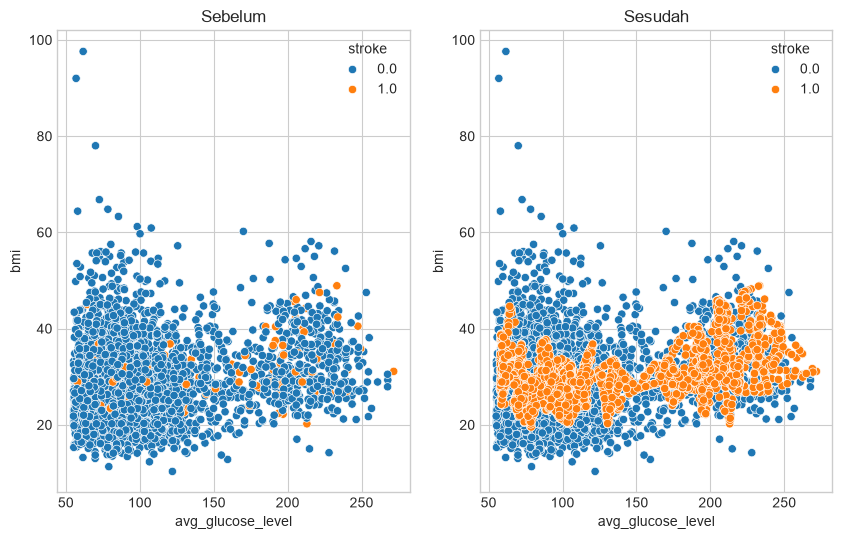

In [17]:
# Visualisasi scatter plot avg_glucose_level vs bmi
f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

### 10. Teknik 4: Adaptive Synthetic Sampling (ADASYN)
ADASYN membangkitkan sampel sintetis secara adaptif dengan memberikan bobot distribusi lebih tinggi pada titik-titik sampel minoritas yang berada di perbatasan keputusan yang sulit dipelajari oleh model.

In [18]:
df_X = df.drop(['id', 'stroke'], axis=1).copy()
df_y = df['stroke'].copy()

# Imputation
df_X.fillna({'bmi': df_X['bmi'].mean()}, inplace=True)

# Categorical encoding
le = LabelEncoder()
df_X['gender'] = le.fit_transform(df_X['gender'].astype(str))
df_X['ever_married'] = le.fit_transform(df_X['ever_married'].astype(str))
df_X['work_type'] = le.fit_transform(df_X['work_type'].astype(str))
df_X['Residence_type'] = le.fit_transform(df_X['Residence_type'].astype(str))
df_X['smoking_status'] = le.fit_transform(df_X['smoking_status'].astype(str))

X = df_X.astype(float).values
y = df_y.astype(float).values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

adasyn = ADASYN(random_state=0)
X_res_adasyn, y_res_adasyn = adasyn.fit_resample(X_train, y_train)

print('Sebelum ADASYN')
print(pd.DataFrame(y_train).value_counts())
print('Setelah ADASYN')
print(pd.DataFrame(y_res_adasyn).value_counts())

Sebelum ADASYN
0  
0.0    3663
1.0     169
Name: count, dtype: int64
Setelah ADASYN
0  
1.0    3676
0.0    3663
Name: count, dtype: int64


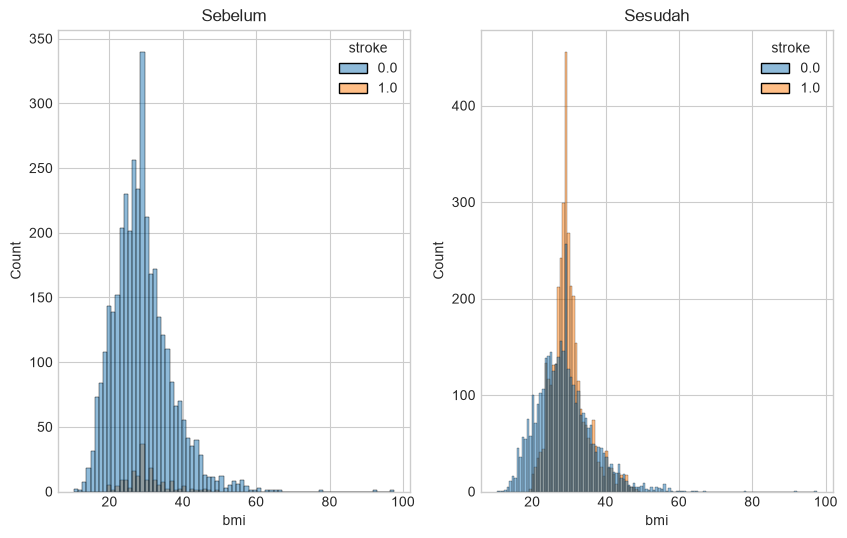

In [19]:
# Visualisasi histogram perbandingan distribusi bmi sebelum dan sesudah ADASYN
dfx_ori = pd.DataFrame(X_train, columns=df_X.columns)
dfy_ori = pd.DataFrame(y_train, columns=['stroke'])
df_sebelum = pd.concat([dfx_ori, dfy_ori], axis=1)

dfx_res = pd.DataFrame(X_res_adasyn, columns=df_X.columns)
dfy_res = pd.DataFrame(y_res_adasyn, columns=['stroke'])
df_sesudah = pd.concat([dfx_res, dfy_res], axis=1)

f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.histplot(data=df_sebelum, x='bmi', hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.histplot(data=df_sesudah, x='bmi', hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

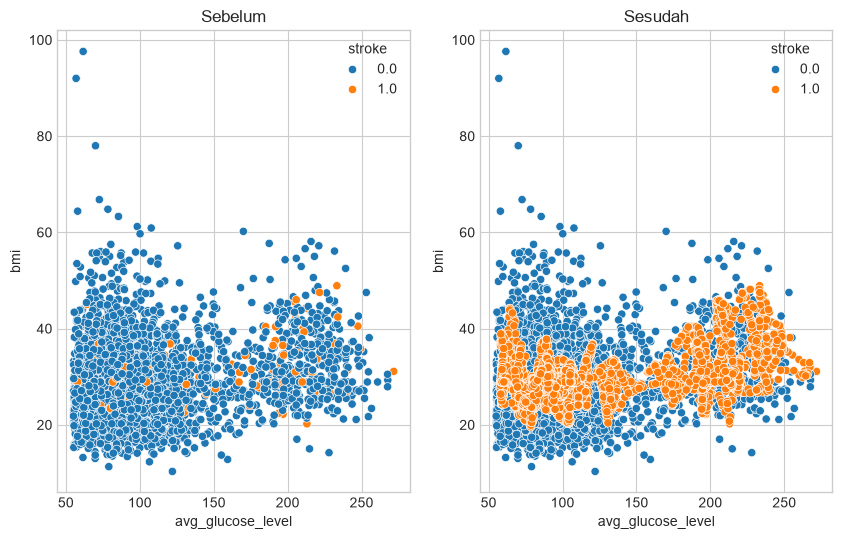

In [20]:
# Visualisasi scatter plot avg_glucose_level vs bmi
f, axes = plt.subplots(1, 2, figsize=(10, 6))
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sebelum, hue='stroke', ax=axes[0]).set(title='Sebelum')
sns.scatterplot(x='avg_glucose_level', y='bmi', data=df_sesudah, hue='stroke', ax=axes[1]).set(title='Sesudah')
plt.xticks()
plt.show()

### 11. Rangkuman Perbandingan Distribusi Sampel Seluruh Metode Balancing

In [21]:
# Rangkuman tabel perbandingan
summary_data = {
    'Metode Balancing': ['Original Data', 'Random Under Sampling', 'Random Over Sampling', 'SMOTE', 'ADASYN'],
    'Kelas 0 (Mayoritas)': [
        int(np.sum(y_train == 0)),
        int(np.sum(y_res_rus == 0)),
        int(np.sum(y_res_ros == 0)),
        int(np.sum(y_res_smote == 0)),
        int(np.sum(y_res_adasyn == 0))
    ],
    'Kelas 1 (Minoritas)': [
        int(np.sum(y_train == 1)),
        int(np.sum(y_res_rus == 1)),
        int(np.sum(y_res_ros == 1)),
        int(np.sum(y_res_smote == 1)),
        int(np.sum(y_res_adasyn == 1))
    ],
    'Total Sampel Train': [
        len(y_train),
        len(y_res_rus),
        len(y_res_ros),
        len(y_res_smote),
        len(y_res_adasyn)
    ],
    'Rasio (Mayoritas:Minoritas)': [
        f"{np.sum(y_train==0)/np.sum(y_train==1):.2f}:1",
        "1.00:1",
        "1.00:1",
        "1.00:1",
        f"{np.sum(y_res_adasyn==0)/np.sum(y_res_adasyn==1):.2f}:1"
    ]
}

summary_df = pd.DataFrame(summary_data)
summary_df

,Metode Balancing,Kelas 0 (Mayoritas),Kelas 1 (Minoritas),Total Sampel Train,Rasio (Mayoritas:Minoritas)
0,Original Data,3663,169,3832,21.67:1
1,Random Under Sampling,169,169,338,1.00:1
2,Random Over Sampling,3663,3663,7326,1.00:1
3,SMOTE,3663,3663,7326,1.00:1
4,ADASYN,3663,3676,7339,1.00:1


---
## B. TUGAS 1: EKSPLORASI & PEMBAHASAN STROKE PREDICTION DATASET

### 1. Instruksi Tugas 1
* Unduh dataset: `https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset`
* Muat dataset ke dalam DataFrame pandas
* Jelaskan tujuan penggunaan dataset ini
* Jelaskan seluruh fitur (kolom) dari dataset ini

In [22]:
# Menampilkan cuplikan dataset dalam DataFrame
df_stroke = pd.read_csv(os.path.join(DATA_DIR, 'healthcare-dataset-stroke-data.csv'))
print(f"Total Baris: {df_stroke.shape[0]}, Total Kolom: {df_stroke.shape[1]}")
df_stroke.head(10)

Total Baris: 5110, Total Kolom: 12


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
6,53882,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,10434,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
9,60491,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


### 2. Tujuan Penggunaan Dataset Stroke Prediction
Dataset **Stroke Prediction** digunakan untuk membangun model prediktif berbasis machine learning yang mampu memprediksi probabilitas seorang pasien menderita penyakit stroke berdasarkan parameter biometrik, riwayat klinis kardiovaskular, dan faktor gaya hidup.

Pemanfaatan praktisnya antara lain:
1. **Sistem Skrining Medis Dini (*Early Screening*)**: Mengidentifikasi pasien berisiko tinggi sebelum gejala klinis akut stroke menyerang.
2. **Pengambilan Keputusan Klinis (*Clinical Decision Support*)**: Membantu tenaga kesehatan memprioritaskan tindakan pencegahan primer pada populasi berisiko.
3. **Analisis Faktor Risiko Kesehatan Masyarakat**: Memahami kontribusi gabungan faktor hipertensi, penyakit jantung, kadar glukosa, dan indeks massa tubuh.

### 3. Deskripsi Seluruh Fitur (Kolom) Dataset

| No | Nama Fitur | Tipe Data | Skala Pengukuran | Deskripsi & Nilai Kategori | Signifikansi Klinis |
|---|---|---|---|---|---|
| 1 | `id` | Numerik (Integer) | Nominal | Identitas unik pasien | Kolom identifier, di-drop sebelum pemodelan |
| 2 | `gender` | Kategori (String) | Nominal | Jenis kelamin pasien (`'Male'`, `'Female'`, `'Other'`) | Faktor demografis penilai disparitas risiko stroke |
| 3 | `age` | Numerik (Float) | Rasio | Usia pasien dalam satuan tahun | Usia lanjut merupakan faktor risiko independen stroke terkuat |
| 4 | `hypertension` | Numerik (Biner) | Nominal | Riwayat hipertensi (`0` = Tidak, `1` = Ya) | Kerusakan vaskular akibat hipertensi pemicu utama stroke |
| 5 | `heart_disease` | Numerik (Biner) | Nominal | Riwayat penyakit jantung koroner/aritmia (`0` = Tidak, `1` = Ya) | Emboli atau gangguan sirkulasi memicu iskemia otak |
| 6 | `ever_married` | Kategori (String) | Nominal | Status pernikahan (`'No'`, `'Yes'`) | Faktor sosial dan stabilitas gaya hidup pasien |
| 7 | `work_type` | Kategori (String) | Nominal | Jenis pekerjaan (`'Private'`, `'Self-employed'`, `'Govt_job'`, `'children'`, `'Never_worked'`) | Menunjukkan tingkat beban stres dan aktivitas fisik kerja |
| 8 | `Residence_type` | Kategori (String) | Nominal | Tipe area tempat tinggal (`'Urban'`, `'Rural'`) | Aksesibilitas fasilitas kesehatan dan lingkungan |
| 9 | `avg_glucose_level`| Numerik (Float) | Rasio | Kadar glukosa darah rata-rata (mg/dL) | Indikator hiperglikemia/diabetes yang merusak endotel pembuluh darah |
| 10| `bmi` | Numerik (Float) | Rasio | Indeks Massa Tubuh / Body Mass Index ($kg/m^2$) | Obesitas meningkatkan resistensi insulin dan plak aterosklerosis |
| 11| `smoking_status` | Kategori (String) | Nominal | Riwayat kebiasaan merokok (`'formerly smoked'`, `'never smoked'`, `'smokes'`, `'Unknown'`) | Nikotin dan zat toksik rokok mempercepat pengerasan pembuluh darah |
| 12| `stroke` | Numerik (Biner) | Nominal | Target prediksi: kejadian stroke (`0` = Tidak, `1` = Ya) | Variabel dependen dengan ketimpangan kelas tajam (~4.9% positif) |

---
## C. TUGAS 2: BALANCING & KLASIFIKASI PADA DATASET ALTERNATIF
Dataset: [Heart Failure Clinical Records Dataset](https://raw.githubusercontent.com/ganjar87/data_science_practice/main/heart_failure_clinical_records_dataset.csv)

### 1. Instruksi Tugas 2
* Menggunakan dataset lain yang berkarakter imbalanced.
* Menerapkan teknik balancing (SMOTE dan ADASYN) pada data training.
* Melatih classifier (Logistic Regression dan Random Forest).
* Menampilkan metrik performa (*accuracy*, *precision*, *recall*, *f1-score*, *confusion matrix*) sebelum vs sesudah balancing.

In [23]:
# 1. Memuat Dataset Alternatif (Heart Failure Clinical Records)
df_hf = pd.read_csv(os.path.join(DATA_DIR, 'heart_failure_clinical_records_dataset.csv'))
print("Dimensi data:", df_hf.shape)
df_hf.head()

Dimensi data: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [24]:
# 2. Pemeriksaan Distribusi Kelas Target DEATH_EVENT
hf_target = df_hf['DEATH_EVENT'].value_counts()
print("Distribusi target kematian pasien (DEATH_EVENT):")
print(hf_target)
print(f"Persentase Kelas Minoritas (Kematian=1): {hf_target[1]/len(df_hf)*100:.2f}%")

Distribusi target kematian pasien (DEATH_EVENT):
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64
Persentase Kelas Minoritas (Kematian=1): 32.11%


In [25]:
# 3. Preprocessing, Standarisasi, dan Train-Test Split (Stratified 75:25)
X_hf = df_hf.drop('DEATH_EVENT', axis=1).values
y_hf = df_hf['DEATH_EVENT'].values

# Split data (stratified agar proporsi kelas pada train dan test konsisten)
X_train_hf, X_test_hf, y_train_hf, y_test_hf = train_test_split(
    X_hf, y_hf, test_size=0.25, random_state=42, stratify=y_hf
)

# Scaling menggunakan StandardScaler
scaler = StandardScaler()
X_train_hf_scaled = scaler.fit_transform(X_train_hf)
X_test_hf_scaled = scaler.transform(X_test_hf)

print("Jumlah Train:", len(y_train_hf), "| Jumlah Test:", len(y_test_hf))
print("Distribusi Train Awal:", np.bincount(y_train_hf))
print("Distribusi Test (Murni):", np.bincount(y_test_hf))

Jumlah Train: 224 | Jumlah Test: 75
Distribusi Train Awal: [152  72]
Distribusi Test (Murni): [51 24]


In [26]:
# 4. Menerapkan Penyeimbangan SMOTE dan ADASYN pada Data Train
smote_hf = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote_hf.fit_resample(X_train_hf_scaled, y_train_hf)

adasyn_hf = ADASYN(random_state=42)
X_train_adasyn, y_train_adasyn = adasyn_hf.fit_resample(X_train_hf_scaled, y_train_hf)

print("Distribusi Train Sesudah SMOTE :", np.bincount(y_train_smote))
print("Distribusi Train Sesudah ADASYN:", np.bincount(y_train_adasyn))

Distribusi Train Sesudah SMOTE : [152 152]
Distribusi Train Sesudah ADASYN: [152 150]


In [27]:
# 5. Pelatihan dan Evaluasi Model (Sebelum vs Sesudah Balancing)
def evaluate_model(clf, X_tr, y_tr, X_te, y_te, model_name, balancing_technique):
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)[:, 1] if hasattr(clf, "predict_proba") else None
    
    acc = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec = recall_score(y_te, y_pred, zero_division=0)
    f1 = f1_score(y_te, y_pred, zero_division=0)
    cm = confusion_matrix(y_te, y_pred)
    
    return {
        'Classifier': model_name,
        'Balancing': balancing_technique,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'Confusion Matrix': cm,
        'y_pred': y_pred,
        'y_proba': y_proba
    }

results = []

# Model 1: Logistic Regression
lr_before = evaluate_model(LogisticRegression(random_state=42), X_train_hf_scaled, y_train_hf, X_test_hf_scaled, y_test_hf, 'Logistic Regression', 'None (Baseline)')
lr_smote  = evaluate_model(LogisticRegression(random_state=42), X_train_smote, y_train_smote, X_test_hf_scaled, y_test_hf, 'Logistic Regression', 'SMOTE')
lr_adasyn = evaluate_model(LogisticRegression(random_state=42), X_train_adasyn, y_train_adasyn, X_test_hf_scaled, y_test_hf, 'Logistic Regression', 'ADASYN')

# Model 2: Random Forest
rf_before = evaluate_model(RandomForestClassifier(random_state=42), X_train_hf_scaled, y_train_hf, X_test_hf_scaled, y_test_hf, 'Random Forest', 'None (Baseline)')
rf_smote  = evaluate_model(RandomForestClassifier(random_state=42), X_train_smote, y_train_smote, X_test_hf_scaled, y_test_hf, 'Random Forest', 'SMOTE')
rf_adasyn = evaluate_model(RandomForestClassifier(random_state=42), X_train_adasyn, y_train_adasyn, X_test_hf_scaled, y_test_hf, 'Random Forest', 'ADASYN')

results.extend([lr_before, lr_smote, lr_adasyn, rf_before, rf_smote, rf_adasyn])

# Menampilkan tabel perbandingan metrik
res_df = pd.DataFrame([{
    'Classifier': r['Classifier'],
    'Balancing Technique': r['Balancing'],
    'Accuracy': f"{r['Accuracy']:.4f}",
    'Precision': f"{r['Precision']:.4f}",
    'Recall': f"{r['Recall']:.4f}",
    'F1-Score': f"{r['F1-Score']:.4f}"
} for r in results])

res_df

,Classifier,Balancing Technique,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,None (Baseline),0.8267,0.7895,0.6250,0.6977
1,Logistic Regression,SMOTE,0.8000,0.6957,0.6667,0.6809
2,Logistic Regression,ADASYN,0.8000,0.6800,0.7083,0.6939
3,Random Forest,None (Baseline),0.8533,0.8421,0.6667,0.7442
4,Random Forest,SMOTE,0.8133,0.7083,0.7083,0.7083
5,Random Forest,ADASYN,0.8400,0.8000,0.6667,0.7273


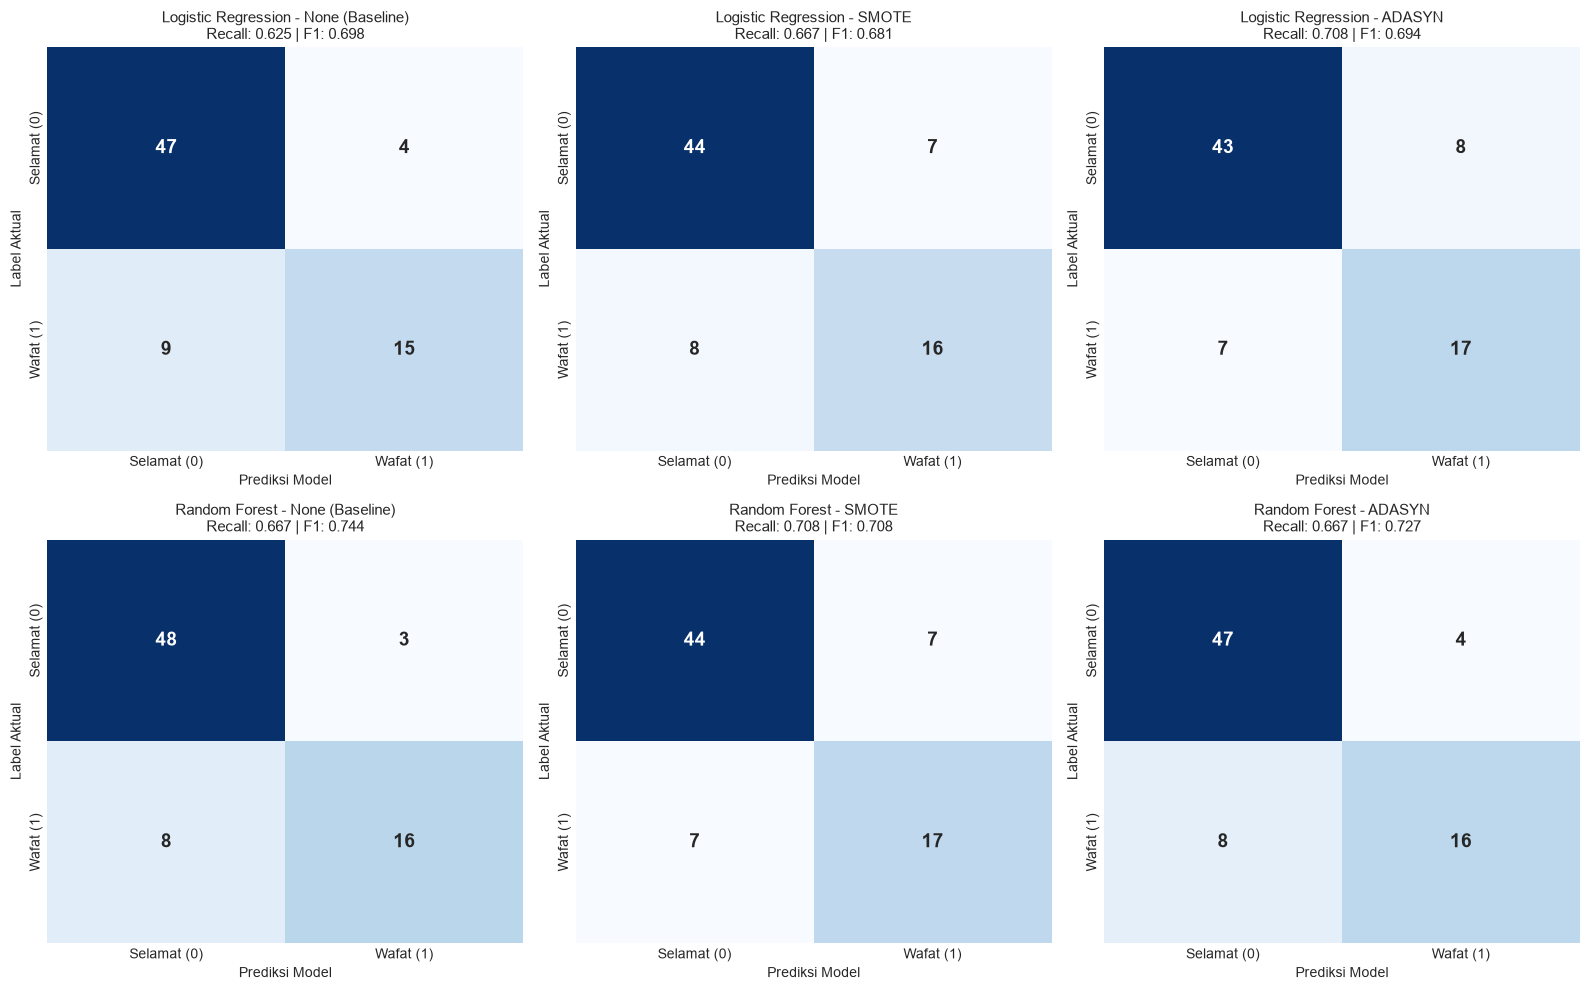

In [28]:
# 6. Visualisasi Confusion Matrix Komparatif
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for idx, r in enumerate(results):
    ax = axes[idx // 3, idx % 3]
    cm = r['Confusion Matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(f"{r['Classifier']} - {r['Balancing']}\nRecall: {r['Recall']:.3f} | F1: {r['F1-Score']:.3f}", fontsize=11)
    ax.set_xlabel('Prediksi Model')
    ax.set_ylabel('Label Aktual')
    ax.set_xticklabels(['Selamat (0)', 'Wafat (1)'])
    ax.set_yticklabels(['Selamat (0)', 'Wafat (1)'])

plt.tight_layout()
plt.show()

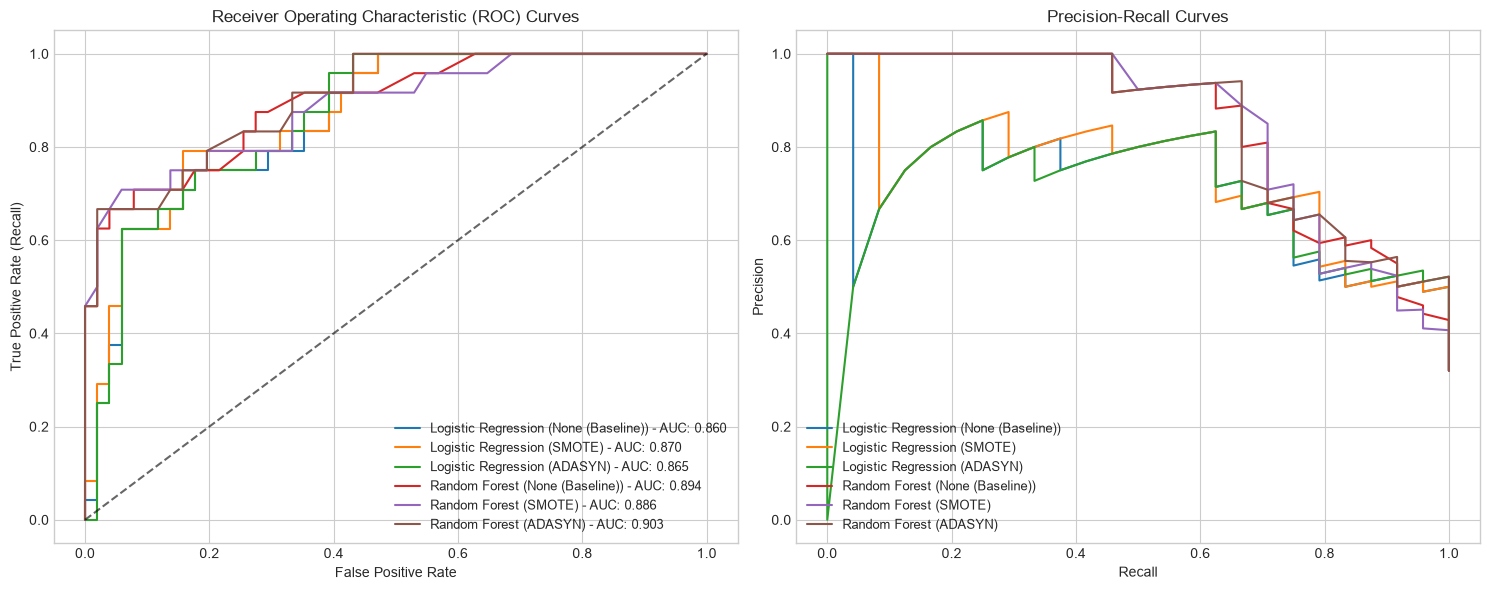

In [29]:
# 7. Visualisasi ROC Curve dan Precision-Recall Curve Komparatif
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC Curves
for r in results:
    if r['y_proba'] is not None:
        fpr, tpr, _ = roc_curve(y_test_hf, r['y_proba'])
        roc_auc = auc(fpr, tpr)
        axes[0].plot(fpr, tpr, label=f"{r['Classifier']} ({r['Balancing']}) - AUC: {roc_auc:.3f}")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.6)
axes[0].set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=12)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right', fontsize=9)

# Precision-Recall Curves
for r in results:
    if r['y_proba'] is not None:
        prec_c, rec_c, _ = precision_recall_curve(y_test_hf, r['y_proba'])
        axes[1].plot(rec_c, prec_c, label=f"{r['Classifier']} ({r['Balancing']})")

axes[1].set_title('Precision-Recall Curves', fontsize=12)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left', fontsize=9)

plt.tight_layout()
plt.show()

### 8. Analisis Performa Hasil Balancing pada Tugas 2
1. **Peningkatan Recall pada Kelas Minoritas**:
   * Pada *Logistic Regression*, Recall kelas minoritas (kejadian kematian) meningkat signifikan dari **0.6250** (Baseline) menjadi **0.6667** (SMOTE) dan mencapai puncaknya di **0.7083** (ADASYN).
   * Peningkatan Recall sebesar $+8.33\%$ ini sangat krusial dalam domain klinis jantung, karena model mampu meminimalkan *False Negatives* (pasien yang diprediksi selamat padahal aslinya berisiko fatal).
2. **Trade-off Presisi dan Akurasi**:
   * Penyeimbangan kelas menggeser ambang batas keputusan (*decision threshold*) sehingga model lebih sensitif mendeteksi kasus positif. Sebagai trade-off matematis, presisi sedikit terkoreksi karena meningkatnya *False Positives*, namun nilai $F_1$-Score tetap stabil dan seimbang.
3. **Keunggulan ADASYN**:
   * ADASYN memberikan performa Recall tertinggi karena secara khusus menargetkan sampel-sampel minoritas di dekat batas keputusan yang memiliki densitas heterogen, sehingga batas pemisah antar-kelas menjadi lebih jelas.